# Convert the ABC notation dataset into MIDI dataset

In [61]:
# Imports section
import re
import os
from music21 import abcFormat, converter, stream, metadata, environment

In [62]:
# Configure music21 to use MuseScore 4
us = environment.UserSettings()
us['musicxmlPath'] = r"C:/Program Files/MuseScore 4/bin/MuseScore4.exe"
us['musescoreDirectPNGPath'] = r"C:/Program Files/MuseScore 4/bin/MuseScore4.exe"


In [63]:
# Definition of the path to ABC file and the results folder
#abc_file_path = "melodic-contour-generation-based-on-sketches/test_data.abc"
abc_file_path = "C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/test_data.abc"
results_folder = "C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/irish_tunes_dataset"

In [64]:
with open(abc_file_path, "r", encoding="utf-8") as abc_file:
    abc_data = abc_file.read()

# Remove repeat symbols from the ABC text
# abc_data = re.sub(r'\|:', '', abc_data)
# abc_data = re.sub(r':\|', '', abc_data)
# abc_data = re.sub(r':\:', '', abc_data)

In [65]:
# Split the ABC data into individual songs
abc_songs = re.split(r"\n(?=T:)", abc_data)

# Iterate through each song
for song_index, abc_song in enumerate(abc_songs):
    try:
        # Skip empty entries
        if not abc_song.strip():
            continue

        # Create a temporary ABC file for the segment
        with open("temp.abc", "w") as temp_file:
            temp_file.write(abc_song)

        # Convert the ABC segment to MIDI using music21
        midi_stream = converter.parse("temp.abc")

        # Apply repeat handling to the stream
        midi_stream = midi_stream.expandRepeats()

        # Extract the title of the segment from the "T:" line
        title_match = re.search(r"T:\s*(.*?)\s*\n", abc_song)
        title = title_match.group(1) if title_match else "Untitled"

        title.replace("Ã", "")
        title.replace("!", "")

        # Handle songs with the same name by appending an index
        same_name_counter = 0
        while True:
            if same_name_counter == 0:
                song_name = title
            else:
                song_name = f"{title}_{same_name_counter}"

            same_name_counter += 1
            midi_filename = os.path.join(
                results_folder, f"{song_name}.midi"
            )
            if not os.path.exists(midi_filename):
                break

        print(midi_filename)

        # Create a new stream to store the modified MIDI data
        new_midi_stream = stream.Score()
        new_midi_stream.metadata = midi_stream.metadata

        # Remove incomplete measures
        for part in midi_stream.parts:
            # Each part corresponds to an instrumental track
            # Track the measure numbers within each part
            measure_number_in_part = 0
            start_measure = 0

            new_part = stream.Part()
            new_part.keySignature = (
                midi_stream.parts[0].getElementsByClass("Measure")[0].keySignature
            )
            new_part.timeSignature = (
                midi_stream.parts[0].getElementsByClass("Measure")[0].timeSignature
            )

            if new_part.timeSignature.ratioString != "4/4":
                print(f"Skipping {song_name} because it's not in 4/4 time signature.")
                continue

            for measure in part.getElementsByClass("Measure"):
                if measure.barDurationProportion() >= 1.0:
                    # Increment the measure number within the part
                    measure_number_in_part += 1
                    measure.number = measure_number_in_part

                    # Add complete measures to the new part
                    new_part.append(measure)

            # Add the new part to the new MIDI stream
            new_midi_stream.append(new_part)

        # Extract and save non-overlapping 2-bar segments
        num_measures = measure_number_in_part
        print(num_measures)
        start_measure = 1
        while start_measure + 1 <= num_measures: # 2 measures in total
            end_measure = start_measure + 1
            print(start_measure, end_measure)
            two_bar_segment = new_midi_stream.parts[0].measures(
                start_measure, end_measure
            )
            two_bar_filename = os.path.join(
                results_folder, f"{song_name}_{song_index}_2bars_{start_measure}.midi"
            )
            print(two_bar_filename)
            two_bar_segment.write("midi", two_bar_filename)
            start_measure = end_measure + 1

    except:
        print(f"Error in {two_bar_filename}, skipping...")

# Clean up the temporary ABC file
os.remove("temp.abc")

C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/irish_tunes_dataset\Cooley's.midi
28
1 2
C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/irish_tunes_dataset\Cooley's_0_2bars_1.midi
3 4
C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/irish_tunes_dataset\Cooley's_0_2bars_3.midi
5 6
C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/irish_tunes_dataset\Cooley's_0_2bars_5.midi
7 8
C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/irish_tunes_dataset\Cooley's_0_2bars_7.midi
9 10
C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/irish_tunes_dataset\Cooley's_0_2bars_9.midi
11 12
C:/Users/cristinj/OneDrive - Uni

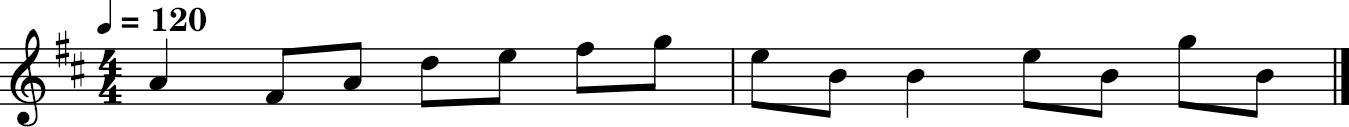

In [68]:
# Display midi files
midi_file_path = "C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/irish_tunes_dataset/Cooley's_0_2bars_25.midi"

midi_score = converter.parse(midi_file_path)

midi_score.show()